# StructML (236605) - Assignment 2: Node and Tuple Embedding


## Part 0 - Setup, data loading, and feature matrix reuse


In [ ]:
import sys, subprocess, os, time, warnings, json
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "relbench[full]", "torch_geometric"])

In [ ]:
from collections import Counter, defaultdict
from itertools import combinations
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

import sklearn
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.kernel_approximation import Nystroem
from sklearn.decomposition import PCA
from sklearn.utils.extmath import randomized_svd
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
)
import xgboost as xgb
from scipy.sparse import csr_matrix, coo_matrix

from relbench.datasets import get_dataset
from relbench.tasks import get_task

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

RNG = np.random.default_rng(42)
torch.manual_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EMB_DIM = 128

print("torch", torch.__version__, "device =", DEVICE)
print("sklearn", sklearn.__version__, " | xgboost", xgb.__version__)

# --- Heartbeat: append-only progress log on shared FS so we can monitor
# from outside the slurm job. The notebook calls hb(...) at every major step.
HB_PATH = "/home/wertheizer/structeredML/HW2/_progress.log"
import datetime, os
def hb(msg):
    """Print + write a timestamped progress line to the heartbeat file."""
    line = f"[{datetime.datetime.now().strftime('%H:%M:%S')}] {msg}"
    print(line, flush=True)
    try:
        with open(HB_PATH, "a") as f:
            f.write(line + "\n")
    except Exception:
        pass

# Truncate the heartbeat file at the start of every run
try: os.unlink(HB_PATH)
except FileNotFoundError: pass
hb(f"START | torch={torch.__version__} device={DEVICE}")

torch 2.11.0+cu128 device = cuda
sklearn 1.6.1  | xgboost 3.2.0
[12:42:29] START | torch=2.11.0+cu128 device=cuda


In [ ]:
dataset = get_dataset("rel-stack", download=False)
db = dataset.get_db()
task = get_task("rel-stack", "user-engagement", download=False)

train_df = task.get_table("train").df.copy()
val_df   = task.get_table("val").df.copy()
test_df  = task.get_table("test").df.copy()

VAL_TIMESTAMP = pd.Timestamp(dataset.val_timestamp)
print("val_timestamp:", VAL_TIMESTAMP)

print("Tables in db:")
for name, t in db.table_dict.items():
    print(f"  {name:12s} rows={len(t.df):>10,} pkey={t.pkey_col!s:<6} time={t.time_col!s:<14} fkeys={t.fkey_col_to_pkey_table}")

Loading Database object from /home/wertheizer/.cache/relbench/rel-stack/db...


Done in 10.98 seconds.


val_timestamp: 2020-10-01 00:00:00
Tables in db:
  badges       rows=   463,463 pkey=Id     time=Date           fkeys={'UserId': 'users'}
  comments     rows=   623,967 pkey=Id     time=CreationDate   fkeys={'UserId': 'users', 'PostId': 'posts'}
  postHistory  rows= 1,175,368 pkey=Id     time=CreationDate   fkeys={'PostId': 'posts', 'UserId': 'users'}
  postLinks    rows=    77,337 pkey=Id     time=CreationDate   fkeys={'PostId': 'posts', 'RelatedPostId': 'posts'}
  posts        rows=   333,893 pkey=Id     time=CreationDate   fkeys={'OwnerUserId': 'users', 'ParentId': 'posts'}
  users        rows=   255,360 pkey=Id     time=CreationDate   fkeys={}
  votes        rows= 1,317,876 pkey=Id     time=CreationDate   fkeys={'PostId': 'posts', 'UserId': 'users'}


### Rebuild the HW1 feature matrix (46 columns at depth=2)


In [ ]:
SCHEMA_FKEYS: List[Tuple[str, str, str]] = []
for child, t in db.table_dict.items():
    for fk_col, parent in t.fkey_col_to_pkey_table.items():
        SCHEMA_FKEYS.append((parent, child, fk_col))
TARGET_FK_COL = "OwnerUserId"
TARGET_FK_PARENT = "users"
SCHEMA_FKEYS.append((TARGET_FK_PARENT, "_target_", TARGET_FK_COL))


def column_dtype_kind(s):
    if pd.api.types.is_datetime64_any_dtype(s): return "timestamp"
    if pd.api.types.is_numeric_dtype(s):        return "numeric"
    return "categorical"

AGGS_FOR_KIND = {"numeric": ["mean", "count", "sum"],
                 "categorical": ["count"],
                 "timestamp": ["min", "max"]}


def enumerate_join_paths(max_depth):
    adj = defaultdict(list)
    for parent, child, fk_col in SCHEMA_FKEYS:
        adj[parent].append((child, parent, child, fk_col))
        adj[child].append((parent, parent, child, fk_col))
    paths = []
    frontier = [("_target_", {"_target_"}, [])]
    for _ in range(max_depth):
        nxt = []
        for cur, visited, path in frontier:
            for nbr, parent, child, fk_col in adj[cur]:
                if nbr in visited: continue
                edge = (cur, nbr, f"{parent}.Id={child}.{fk_col}")
                paths.append(path + [edge])
                nxt.append((nbr, visited | {nbr}, path + [edge]))
        frontier = nxt
    return paths


def _filter_by_time(df, time_col, cutoff_ts):
    if cutoff_ts is None or time_col is None or time_col not in df.columns:
        return df
    return df[df[time_col] <= cutoff_ts]


def auto_features(target_df, max_depth=2, split="train", verbose=False):
    paths = enumerate_join_paths(max_depth)
    target = target_df.copy()
    target["_row_id"] = np.arange(len(target))
    val_cut = VAL_TIMESTAMP if split == "val" else None

    def src_df(name):
        return _filter_by_time(db.table_dict[name].df, db.table_dict[name].time_col, val_cut)

    users_df = src_df("users")
    users_time_col = db.table_dict["users"].time_col
    per_path = []
    for path in tqdm(paths, desc=f"auto_features[{split}]", disable=not verbose):
        tables_seq = [edge[1] for edge in path]
        depth = len(tables_seq)
        leaf_table = tables_seq[-1]
        leaf_df = src_df(leaf_table)
        leaf_time_col = db.table_dict[leaf_table].time_col
        prefix = f"d{depth}__" + "_".join(tables_seq)

        if depth == 1:
            joined = target[["_row_id", "OwnerUserId", "timestamp"]].merge(
                users_df, left_on="OwnerUserId", right_on="Id", how="left")
            if split == "train" and users_time_col in joined.columns:
                m = joined[users_time_col].isna() | (joined[users_time_col] <= joined["timestamp"])
                joined = joined[m]
        elif depth == 2:
            user_fk = next(c for c, t in db.table_dict[leaf_table].fkey_col_to_pkey_table.items() if t == "users")
            joined = (target[["_row_id", "OwnerUserId", "timestamp"]]
                      .merge(users_df[["Id"]], left_on="OwnerUserId", right_on="Id", how="left")
                      .merge(leaf_df, left_on="Id", right_on=user_fk, how="inner",
                             suffixes=("", f"_{leaf_table}")))
            if split == "train" and leaf_time_col is not None:
                cand = f"{leaf_time_col}_{leaf_table}"
                if cand not in joined.columns: cand = leaf_time_col
                if cand in joined.columns:
                    joined = joined[joined[cand] <= joined["timestamp"]]
        else:
            raise NotImplementedError

        leaf_pk = db.table_dict[leaf_table].pkey_col
        leaf_fks = set(db.table_dict[leaf_table].fkey_col_to_pkey_table.keys())
        skip_cols = {leaf_pk} | leaf_fks | {"AccountId"}
        grp = joined.groupby("_row_id", sort=False)
        agg_cols = {}
        for col in leaf_df.columns:
            if col in skip_cols: continue
            suffixed = f"{col}_{leaf_table}"
            cand = suffixed if suffixed in joined.columns else col
            if cand not in joined.columns: continue
            kind = column_dtype_kind(joined[cand])
            if joined[cand].dtype == bool: kind = "categorical"
            for aggn in AGGS_FOR_KIND[kind]:
                try:
                    res = grp[cand].count() if aggn == "count" else grp[cand].agg(aggn)
                except Exception:
                    continue
                agg_cols[f"{prefix}__{col}__{aggn}"] = res
        if agg_cols:
            per_path.append(pd.DataFrame(agg_cols))

    all_feats = pd.concat(per_path, axis=1) if per_path else pd.DataFrame(index=pd.Index([], name="_row_id"))
    fm = target.merge(all_feats, left_on="_row_id", right_index=True, how="left").drop(columns=["_row_id"])
    count_cols = [c for c in fm.columns if c.endswith("__count")]
    fm[count_cols] = fm[count_cols].fillna(0)
    return fm


hb("auto_features start")
t0 = time.time()
train_feat = auto_features(train_df, max_depth=2, split="train", verbose=True)
val_feat   = auto_features(val_df,   max_depth=2, split="val",   verbose=False)
hb(f"auto_features done in {time.time()-t0:.1f}s | train={train_feat.shape} val={val_feat.shape}")

[12:42:41] auto_features start


auto_features[train]:   0%|          | 0/6 [00:00<?, ?it/s]

auto_features[train]:  17%|█▋        | 1/6 [00:00<00:03,  1.35it/s]

auto_features[train]:  33%|███▎      | 2/6 [00:03<00:07,  1.82s/it]

auto_features[train]:  50%|█████     | 3/6 [00:12<00:15,  5.25s/it]

auto_features[train]:  67%|██████▋   | 4/6 [00:33<00:22, 11.48s/it]

auto_features[train]:  83%|████████▎ | 5/6 [00:37<00:08,  8.85s/it]

auto_features[train]: 100%|██████████| 6/6 [00:38<00:00,  5.94s/it]

auto_features[train]: 100%|██████████| 6/6 [00:38<00:00,  6.36s/it]

[12:43:24] auto_features done in 42.9s | train=(1360850, 49) val=(85838, 49)


#Part 1


In [ ]:
def numericize_for_kpca(fm: pd.DataFrame):
    """Return (X_array, kept_cols) for kernel PCA.
    - drop label, OwnerUserId
    - drop object/text cols
    - timestamps -> days-since (target_timestamp - col_value).total_seconds()/86400
    - drop cols that are all-NaN
    - median impute (later)
    """
    target_ts = fm["timestamp"]
    drop = {"contribution", "OwnerUserId", "timestamp"}
    cols = [c for c in fm.columns if c not in drop]
    out = {}
    for c in cols:
        s = fm[c]
        if pd.api.types.is_datetime64_any_dtype(s):
            delta = (target_ts - s).dt.total_seconds() / 86400.0
            out[c] = delta.astype("float64").values
        elif pd.api.types.is_numeric_dtype(s):
            out[c] = s.astype("float64").values
        # else: drop text/object
    df = pd.DataFrame(out)
    # drop all-NaN cols
    keep = df.columns[df.notna().any()].tolist()
    df = df[keep]
    return df, keep


X_tr_num, kpca_cols = numericize_for_kpca(train_feat)
X_va_num, _         = numericize_for_kpca(val_feat)
# align columns (val may be missing some that train has, or vice-versa)
X_va_num = X_va_num.reindex(columns=kpca_cols)
print("Numeric matrix shapes:", X_tr_num.shape, X_va_num.shape, "| kept", len(kpca_cols), "cols")

# Median-impute (fit on train, apply to val)
imputer_kpca = SimpleImputer(strategy="median").fit(X_tr_num.values)
X_tr_imp = imputer_kpca.transform(X_tr_num.values)
X_va_imp = imputer_kpca.transform(X_va_num.values)
# Standardize first - RBF kernel is scale-sensitive
scaler_kpca = StandardScaler().fit(X_tr_imp)
X_tr_sc = scaler_kpca.transform(X_tr_imp)
X_va_sc = scaler_kpca.transform(X_va_imp)
print("After impute+scale:", X_tr_sc.shape, X_va_sc.shape,
      "| any NaN?", np.isnan(X_tr_sc).any(), np.isnan(X_va_sc).any())

Numeric matrix shapes: (1360850, 45) (85838, 45) | kept 45 cols


After impute+scale: (1360850, 45) (85838, 45) | any NaN? False False


In [ ]:
# Nystroem-approximated RBF kernel feature map, then PCA to k=128
t0 = time.time()
N_COMPONENTS_NYS = 512   # Nystroem feature-map size; PCA reduces this to 128
gamma = 1.0 / X_tr_sc.shape[1]  # sklearn default for RBF
nys = Nystroem(kernel="rbf", gamma=gamma, n_components=N_COMPONENTS_NYS,
               random_state=42, n_jobs=-1)
Z_tr_nys = nys.fit_transform(X_tr_sc)
Z_va_nys = nys.transform(X_va_sc)
pca = PCA(n_components=EMB_DIM, random_state=42).fit(Z_tr_nys)
emb_kpca_train = pca.transform(Z_tr_nys).astype("float32")
emb_kpca_val   = pca.transform(Z_va_nys).astype("float32")
print(f"Kernel PCA in {time.time()-t0:.1f}s | train {emb_kpca_train.shape} | val {emb_kpca_val.shape}")
print(f"Explained variance (first 10):", pca.explained_variance_ratio_[:10].round(4))
print(f"Total explained variance @ k={EMB_DIM}: {pca.explained_variance_ratio_.sum():.4f}")
hb(f"Q1 KPCA done | exp_var={pca.explained_variance_ratio_.sum():.4f}")

Kernel PCA in 11.5s | train (1360850, 128) | val (85838, 128)
Explained variance (first 10): [0.2868 0.1388 0.0757 0.0531 0.0478 0.0342 0.0299 0.0259 0.0224 0.0214]
Total explained variance @ k=128: 0.9856
[12:43:42] Q1 KPCA done | exp_var=0.9856


## PyG heterograph + statistics


In [ ]:
# Build heterograph via relbench helper if available, else construct from db directly.
from torch_geometric.data import HeteroData
from torch_geometric.utils import to_undirected

def build_hetero(db, cutoff_ts):
    """Build a HeteroData graph: one node-type per table, edges from PK-FK pairs.
    Keeps only tuples whose time_col <= cutoff_ts (rows with NaT time also kept,
    since their creation time is unknown - matches HW1's behaviour for `users`)."""
    hd = HeteroData()
    # Build per-table id->index maps after time filter
    id_to_idx = {}
    for name, t in db.table_dict.items():
        df = t.df
        if t.time_col is not None and t.time_col in df.columns:
            df = df[df[t.time_col].isna() | (df[t.time_col] <= cutoff_ts)]
        pk = t.pkey_col
        if pk is None:
            # tables without explicit PK (postLinks etc.) - use positional index
            ids = np.arange(len(df))
            id_to_idx[name] = (df, dict(enumerate(ids)), None)
        else:
            ids = df[pk].values
            id_to_idx[name] = (df, {int(v): i for i, v in enumerate(ids)}, pk)
        hd[name].num_nodes = len(df)
    # Edges from FK columns
    for child, t in db.table_dict.items():
        df_child, child_map, child_pk = id_to_idx[child]
        for fk_col, parent in t.fkey_col_to_pkey_table.items():
            df_parent, parent_map, _ = id_to_idx[parent]
            if fk_col not in df_child.columns: continue
            fk_vals = df_child[fk_col].values
            src_local = np.arange(len(df_child))
            mask = ~pd.isna(fk_vals)
            src_local = src_local[mask]
            tgt_ids = fk_vals[mask]
            # map FK -> parent local idx
            tgt_local = np.fromiter(
                (parent_map.get(int(v), -1) for v in tgt_ids),
                dtype=np.int64, count=len(tgt_ids))
            keep = tgt_local >= 0
            src_local = src_local[keep].astype(np.int64)
            tgt_local = tgt_local[keep]
            if len(src_local) == 0: continue
            edge_index = torch.tensor(np.stack([src_local, tgt_local]), dtype=torch.long)
            rel = f"{child}__{fk_col}__{parent}"
            hd[child, rel, parent].edge_index = edge_index
    # capture the per-type local id maps (needed later to look up specific users)
    hd._id_to_idx = {k: v[1] for k, v in id_to_idx.items()}
    hd._dfs       = {k: v[0] for k, v in id_to_idx.items()}
    return hd

t0 = time.time()
hetero = build_hetero(db, VAL_TIMESTAMP)
print(f"Built heterograph in {time.time()-t0:.1f}s")
print("Node types and counts:")
for nt in hetero.node_types:
    print(f"  {nt:12s} {hetero[nt].num_nodes:>10,}")
print("Edge types:")
for et in hetero.edge_types:
    print(f"  {et[0]:>12s} --{et[1]:40s}-> {et[2]:<12s}   E={hetero[et].edge_index.shape[1]:>10,}")

Built heterograph in 3.0s
Node types and counts:
  badges          448,358
  comments        606,124
  postHistory   1,141,610
  postLinks        74,435
  posts           324,981
  users           247,398
  votes         1,278,841
Edge types:
        badges --badges__UserId__users                   -> users          E=   448,358
      comments --comments__UserId__users                 -> users          E=   594,598
      comments --comments__PostId__posts                 -> posts          E=   606,124
   postHistory --postHistory__PostId__posts              -> posts          E= 1,141,610
   postHistory --postHistory__UserId__users              -> users          E= 1,068,079
     postLinks --postLinks__PostId__posts                -> posts          E=    58,844
     postLinks --postLinks__RelatedPostId__posts         -> posts          E=    72,771
         posts --posts__OwnerUserId__users               -> users          E=   319,806
         posts --posts__ParentId__posts              

In [ ]:
# Convert to homogeneous
homo = hetero.to_homogeneous()
ei = homo.edge_index
N = homo.num_nodes
E_directed = ei.shape[1]
print(f"Homogeneous graph: N={N:,}  E(directed)={E_directed:,}")

# --- Q2 statistics on undirected version ---
# Build a deduplicated undirected edge list for stats
src = ei[0].numpy()
dst = ei[1].numpy()
# enforce src<dst, dedupe
lo = np.minimum(src, dst); hi = np.maximum(src, dst)
mask = lo != hi  # drop self-loops for degree counting
lo, hi = lo[mask], hi[mask]
und_pairs = np.unique(np.stack([lo, hi], axis=1), axis=0)
E_undirected = und_pairs.shape[0]
deg = np.zeros(N, dtype=np.int64)
np.add.at(deg, und_pairs[:, 0], 1)
np.add.at(deg, und_pairs[:, 1], 1)
print(f"Edges (undirected, deduped, no self-loops): {E_undirected:,}")
print(f"Degree stats: min={deg.min()}  max={deg.max()}  mean={deg.mean():.2f}  median={int(np.median(deg))}")
hb(f"Q2 graph done | N={N:,} E_und={E_undirected:,} deg_mean={deg.mean():.2f}")

Homogeneous graph: N=4,121,747  E(directed)=5,642,180


Edges (undirected, deduped, no self-loops): 5,642,180
Degree stats: min=0  max=68018  mean=2.74  median=2
[12:44:01] Q2 graph done | N=4,121,747 E_und=5,642,180 deg_mean=2.74


## Laplacian eigenmaps via randomized_svd


In [ ]:
t0 = time.time()
rows = np.concatenate([und_pairs[:, 0], und_pairs[:, 1]])
cols = np.concatenate([und_pairs[:, 1], und_pairs[:, 0]])
data = np.ones(len(rows), dtype=np.float32)
A = csr_matrix((data, (rows, cols)), shape=(N, N))
print(f"Built CSR adjacency in {time.time()-t0:.1f}s | nnz={A.nnz:,}")

t0 = time.time()
U, S, Vt = randomized_svd(A, n_components=EMB_DIM + 1, random_state=42,
                          n_iter=5, n_oversamples=20)
# drop the leading (constant-like) component for an eigenmap-style embedding
emb_lap = (U[:, 1:EMB_DIM+1] * S[1:EMB_DIM+1]).astype("float32")
print(f"randomized_svd in {time.time()-t0:.1f}s | emb_lap shape {emb_lap.shape}")
hb(f"Q3a Laplacian done | shape={emb_lap.shape}")

Built CSR adjacency in 0.4s | nnz=11,284,360


randomized_svd in 186.4s | emb_lap shape (4121747, 128)
[12:47:08] Q3a Laplacian done | shape=(4121747, 128)


##Node2Vec


In [ ]:
from torch_geometric.nn import Node2Vec

def train_node2vec(edge_index, num_nodes, dim=128, walk_length=24, context_size=5,
                   walks_per_node=10, num_negative_samples=1, p=1.0, q=1.0,
                   batch_size=128, epochs=25, lr=0.01, device=DEVICE, verbose=True,
                   num_workers=4):
    model = Node2Vec(edge_index, embedding_dim=dim, walk_length=walk_length,
                     context_size=context_size, walks_per_node=walks_per_node,
                     num_negative_samples=num_negative_samples, p=p, q=q,
                     sparse=True, num_nodes=num_nodes).to(device)
    loader = model.loader(batch_size=batch_size, shuffle=True,
                          num_workers=num_workers)
    opt = torch.optim.SparseAdam(list(model.parameters()), lr=lr)
    hb(f"Node2Vec start | epochs={epochs} batch={batch_size} workers={num_workers}")
    for ep in range(epochs):
        model.train()
        t_ep = time.time()
        total = 0.0; n = 0
        for pos_rw, neg_rw in loader:
            opt.zero_grad()
            loss = model.loss(pos_rw.to(device), neg_rw.to(device))
            loss.backward()
            opt.step()
            total += float(loss); n += 1
        hb(f"n2v ep {ep+1}/{epochs} loss={total/max(n,1):.4f} ({time.time()-t_ep:.1f}s)")
    model.eval()
    with torch.no_grad():
        emb = model.embedding.weight.detach().cpu().numpy().astype("float32")
    return emb

# Build undirected edge_index for the homogeneous graph (Node2Vec walks need both
# directions to flow freely).
ei_und = torch.tensor(np.stack([np.concatenate([und_pairs[:, 0], und_pairs[:, 1]]),
                                np.concatenate([und_pairs[:, 1], und_pairs[:, 0]])]),
                       dtype=torch.long)

t0 = time.time()
emb_n2v = train_node2vec(ei_und, N, dim=EMB_DIM, walk_length=24, context_size=5,
                          batch_size=128, epochs=25, lr=0.01, device=DEVICE, verbose=True)
print(f"Node2Vec trained in {time.time()-t0:.1f}s | shape {emb_n2v.shape}")

[12:47:13] Node2Vec start | epochs=25 batch=128 workers=4


[12:50:02] n2v ep 1/25 loss=2.6402 (168.9s)


[12:53:01] n2v ep 2/25 loss=0.9354 (179.3s)


[12:56:34] n2v ep 3/25 loss=0.8017 (212.7s)


[13:00:32] n2v ep 4/25 loss=0.7722 (237.9s)


[13:04:26] n2v ep 5/25 loss=0.7608 (234.1s)


... (17 outputs left out)

[14:09:27] n2v ep 23/25 loss=0.7505 (232.0s)


[14:12:49] n2v ep 24/25 loss=0.7505 (201.3s)


[14:15:50] n2v ep 25/25 loss=0.7505 (181.1s)


Node2Vec trained in 5323.8s | shape (4121747, 128)


## Metapath2Vec


In [ ]:
from torch_geometric.nn import MetaPath2Vec

# Compose the heterograph edges we need for the metapath user-post-comment-user.
# Need:  user→post,  post→comment,  comment→user  (and the reverses for undirected).
def get_or_make_edge(hd, src_type, rel_substr, dst_type):
    """Find an edge type (src_type, rel, dst_type) whose rel contains rel_substr.
    Returns the edge_index, or None if not present."""
    for et in hd.edge_types:
        s, r, d = et
        if s == src_type and d == dst_type and rel_substr in r:
            return hd[et].edge_index
    return None

# In rel-stack: posts.OwnerUserId -> users.Id  (so edge type is posts -> users)
# We need user→post (reverse) and post→user (forward).
# comments.UserId -> users.Id  (comments -> users)
# comments.PostId -> posts.Id  (comments -> posts)
mp_edges = {}
# user -> post  (reverse of posts.OwnerUserId)
posts_owner = get_or_make_edge(hetero, "posts", "OwnerUserId", "users")
if posts_owner is not None:
    mp_edges[("users", "owns", "posts")] = posts_owner.flip(0)
    mp_edges[("posts", "ownedBy", "users")] = posts_owner
# post -> comment (reverse of comments.PostId -> posts)
comments_post = get_or_make_edge(hetero, "comments", "PostId", "posts")
if comments_post is not None:
    mp_edges[("posts", "hasComment", "comments")] = comments_post.flip(0)
    mp_edges[("comments", "onPost", "posts")] = comments_post
# comment -> user (comments.UserId -> users)
comments_user = get_or_make_edge(hetero, "comments", "UserId", "users")
if comments_user is not None:
    mp_edges[("comments", "byUser", "users")] = comments_user
    mp_edges[("users", "wrote", "comments")] = comments_user.flip(0)

metapath = [
    ("users", "owns", "posts"),
    ("posts", "hasComment", "comments"),
    ("comments", "byUser", "users"),
]

# Build a minimal HeteroData with only the edges we need (plus the node counts)
hd_mp = HeteroData()
for nt in ["users", "posts", "comments"]:
    hd_mp[nt].num_nodes = hetero[nt].num_nodes
for et, ei in mp_edges.items():
    hd_mp[et].edge_index = ei
print("Metapath2Vec input graph:")
for nt in hd_mp.node_types:
    print(f"  {nt:10s} N={hd_mp[nt].num_nodes:,}")
for et in hd_mp.edge_types:
    print(f"  {et}  E={hd_mp[et].edge_index.shape[1]:,}")


def train_metapath2vec(hd, metapath, dim=128, walk_length=24, context_size=5,
                       walks_per_node=10, num_negative_samples=5,
                       batch_size=128, epochs=25, lr=0.01, device=DEVICE, verbose=True,
                       num_workers=4):
    model = MetaPath2Vec(hd.edge_index_dict, embedding_dim=dim, metapath=metapath,
                         walk_length=walk_length, context_size=context_size,
                         walks_per_node=walks_per_node,
                         num_negative_samples=num_negative_samples,
                         sparse=True).to(device)
    loader = model.loader(batch_size=batch_size, shuffle=True, num_workers=num_workers)
    opt = torch.optim.SparseAdam(list(model.parameters()), lr=lr)
    hb(f"Metapath2Vec start | epochs={epochs} batch={batch_size} workers={num_workers}")
    for ep in range(epochs):
        model.train()
        t_ep = time.time()
        total = 0.0; n = 0
        for pos_rw, neg_rw in loader:
            opt.zero_grad()
            loss = model.loss(pos_rw.to(device), neg_rw.to(device))
            loss.backward(); opt.step()
            total += float(loss); n += 1
        hb(f"m2v ep {ep+1}/{epochs} loss={total/max(n,1):.4f} ({time.time()-t_ep:.1f}s)")
    model.eval()
    out = {}
    for nt in hd.node_types:
        with torch.no_grad():
            out[nt] = model(nt).detach().cpu().numpy().astype("float32")
    return out

t0 = time.time()
emb_m2v_by_type = train_metapath2vec(hd_mp, metapath, dim=EMB_DIM, walk_length=24,
                                      context_size=5, batch_size=128, epochs=25,
                                      lr=0.01, device=DEVICE, verbose=True)
print(f"Metapath2Vec trained in {time.time()-t0:.1f}s")
for nt, e in emb_m2v_by_type.items():
    print(f"  {nt}: {e.shape}")

Metapath2Vec input graph:
  users      N=247,398
  posts      N=324,981
  comments   N=606,124
  ('users', 'owns', 'posts')  E=319,806
  ('posts', 'ownedBy', 'users')  E=319,806
  ('posts', 'hasComment', 'comments')  E=606,124
  ('comments', 'onPost', 'posts')  E=606,124
  ('comments', 'byUser', 'users')  E=594,598
  ('users', 'wrote', 'comments')  E=594,598


[14:15:53] Metapath2Vec start | epochs=25 batch=128 workers=4


[14:16:56] m2v ep 1/25 loss=3.1661 (62.7s)


[14:17:58] m2v ep 2/25 loss=1.1336 (62.6s)


[14:19:01] m2v ep 3/25 loss=0.8414 (62.5s)


[14:20:03] m2v ep 4/25 loss=0.7744 (62.4s)


... (18 outputs left out)

[14:39:59] m2v ep 23/25 loss=0.7046 (62.3s)


[14:41:02] m2v ep 24/25 loss=0.7046 (63.0s)


[14:42:05] m2v ep 25/25 loss=0.7047 (62.2s)


Metapath2Vec trained in 1573.4s
  users: (247398, 128)
  posts: (324981, 128)
  comments: (606124, 128)


### Mapping embeddings back to target rows


In [ ]:
# Find the homogeneous-graph offset for each node type so we can index into emb_lap/emb_n2v
# (to_homogeneous concatenates node types in the order returned by `hetero.node_types`)
node_types = list(hetero.node_types)
offsets = {}
cum = 0
for nt in node_types:
    offsets[nt] = cum
    cum += hetero[nt].num_nodes
print("Homogeneous offsets:", offsets)

users_local_idx = hetero._id_to_idx["users"]   # users.Id -> local idx in users node-type
posts_local_idx = hetero._id_to_idx["posts"]
comments_local_idx = hetero._id_to_idx["comments"]


def user_local_for_owner(owner_id):
    """Map a target row's OwnerUserId to a local users-table node index, or -1."""
    try:
        return users_local_idx.get(int(owner_id), -1)
    except (ValueError, TypeError):
        return -1


# Pre-build a fast vectorized lookup: users.Id -> users-local-idx using pandas.Series.map
_users_id_to_loc = pd.Series(users_local_idx)  # Index=user Id, values=local idx


def _owner_to_users_loc(owner_ids: np.ndarray) -> np.ndarray:
    """Vectorized: target row's OwnerUserId -> users-local index, or -1 if missing."""
    s = pd.Series(owner_ids).map(_users_id_to_loc)
    return s.fillna(-1).astype("int64").values


def per_row_embedding_from_node_emb(target_df, node_emb, users_offset, dim):
    """Vectorized lookup. Rows whose user is not in the graph get a zero vector."""
    locs = _owner_to_users_loc(target_df["OwnerUserId"].values)
    out = np.zeros((len(target_df), dim), dtype="float32")
    mask = locs >= 0
    out[mask] = node_emb[users_offset + locs[mask]]
    return out


def per_row_embedding_from_user_only(target_df, user_emb, dim):
    """Same lookup, but emb is already per-user (e.g. metapath2vec users matrix)."""
    locs = _owner_to_users_loc(target_df["OwnerUserId"].values)
    out = np.zeros((len(target_df), dim), dtype="float32")
    mask = locs >= 0
    out[mask] = user_emb[locs[mask]]
    return out


u_off = offsets["users"]
emb_lap_train  = per_row_embedding_from_node_emb(train_df, emb_lap, u_off, EMB_DIM)
emb_lap_val    = per_row_embedding_from_node_emb(val_df,   emb_lap, u_off, EMB_DIM)
emb_n2v_train  = per_row_embedding_from_node_emb(train_df, emb_n2v, u_off, EMB_DIM)
emb_n2v_val    = per_row_embedding_from_node_emb(val_df,   emb_n2v, u_off, EMB_DIM)
emb_m2v_train  = per_row_embedding_from_user_only(train_df, emb_m2v_by_type["users"], EMB_DIM)
emb_m2v_val    = per_row_embedding_from_user_only(val_df,   emb_m2v_by_type["users"], EMB_DIM)

# Coverage: how many rows mapped to a real node?
def coverage(arr):
    return (np.abs(arr).sum(axis=1) > 0).mean()
print("Train coverage (non-zero rows):",
      f"lap={coverage(emb_lap_train):.3f}  n2v={coverage(emb_n2v_train):.3f}  m2v={coverage(emb_m2v_train):.3f}")
print("Val   coverage (non-zero rows):",
      f"lap={coverage(emb_lap_val):.3f}    n2v={coverage(emb_n2v_val):.3f}    m2v={coverage(emb_m2v_val):.3f}")

# Cache embeddings to disk
np.savez_compressed("/home/wertheizer/structeredML/HW2/embeddings.npz",
    kpca_train=emb_kpca_train, kpca_val=emb_kpca_val,
    lap_train=emb_lap_train,   lap_val=emb_lap_val,
    n2v_train=emb_n2v_train,   n2v_val=emb_n2v_val,
    m2v_train=emb_m2v_train,   m2v_val=emb_m2v_val,
    emb_lap_raw=emb_lap, emb_n2v_raw=emb_n2v,
    emb_m2v_users=emb_m2v_by_type["users"])
print("Saved embeddings.npz")
hb("embeddings.npz saved (all 4 base embeddings)")

Homogeneous offsets: {'badges': 0, 'comments': 448358, 'postHistory': 1054482, 'postLinks': 2196092, 'posts': 2270527, 'users': 2595508, 'votes': 2842906}


Train coverage (non-zero rows): lap=1.000  n2v=1.000  m2v=1.000
Val   coverage (non-zero rows): lap=1.000    n2v=1.000    m2v=1.000


Saved embeddings.npz
[14:46:15] embeddings.npz saved (all 4 base embeddings)


## Part 2 - Analysis
### Q4. Visual analysis - t-SNE 4×4 grid


In [ ]:
rng = np.random.default_rng(42)
y_val = val_df["contribution"].astype(int).values
pos_idx = np.where(y_val == 1)[0]
neg_idx = np.where(y_val == 0)[0]
n_each = min(200, len(pos_idx), len(neg_idx))
sample_pos = rng.choice(pos_idx, size=n_each, replace=False)
sample_neg = rng.choice(neg_idx, size=n_each, replace=False)
sample = np.concatenate([sample_pos, sample_neg])
print(f"t-SNE sample: {n_each} positives + {n_each} negatives = {len(sample)} rows")

# --- Build coloring vectors for each sampled row ---
# (a) label: already y_val[sample]
labels = y_val[sample]

# (b) node degree of the user (from the homogeneous graph)
owner_ids_sample = val_df["OwnerUserId"].iloc[sample].values
_locs = _owner_to_users_loc(owner_ids_sample)
sample_deg = np.where(_locs >= 0, deg[u_off + np.where(_locs >= 0, _locs, 0)], -1)

def deg_bucket(d):
    if d <= 0: return "0"
    if d <= 10: return "1-10"
    if d <= 100: return "11-100"
    return ">100"
sample_deg_bucket = np.array([deg_bucket(d) for d in sample_deg])

# (c) posts above/below 2
posts_per_user = (db.table_dict["posts"].df
                  .dropna(subset=["OwnerUserId"])
                  .groupby("OwnerUserId").size())
sample_posts = np.array([int(posts_per_user.get(int(o), 0)) if not pd.isna(o) else 0
                          for o in owner_ids_sample])
sample_posts_bucket = np.where(sample_posts > 2, ">2 posts", "≤2 posts")

# (d) badges >= 1
badges_per_user = (db.table_dict["badges"].df
                    .dropna(subset=["UserId"])
                    .groupby("UserId").size())
sample_has_badge = np.array(["≥1 badge" if (not pd.isna(o)) and badges_per_user.get(int(o), 0) >= 1
                              else "0 badges" for o in owner_ids_sample])

t-SNE sample: 200 positives + 200 negatives = 400 rows


In [ ]:
def tsne_2d(X, seed=42, perplexity=30):
    return TSNE(n_components=2, perplexity=perplexity, random_state=seed,
                init="pca", learning_rate="auto").fit_transform(X)

emb_sources = {
    "Kernel PCA":         emb_kpca_val[sample],
    "Laplacian eigenmaps": emb_lap_val[sample],
    "Node2Vec":           emb_n2v_val[sample],
    "Metapath2Vec":       emb_m2v_val[sample],
}
tsne_xy = {name: tsne_2d(arr) for name, arr in emb_sources.items()}
print("t-SNE projections computed.")

t-SNE projections computed.


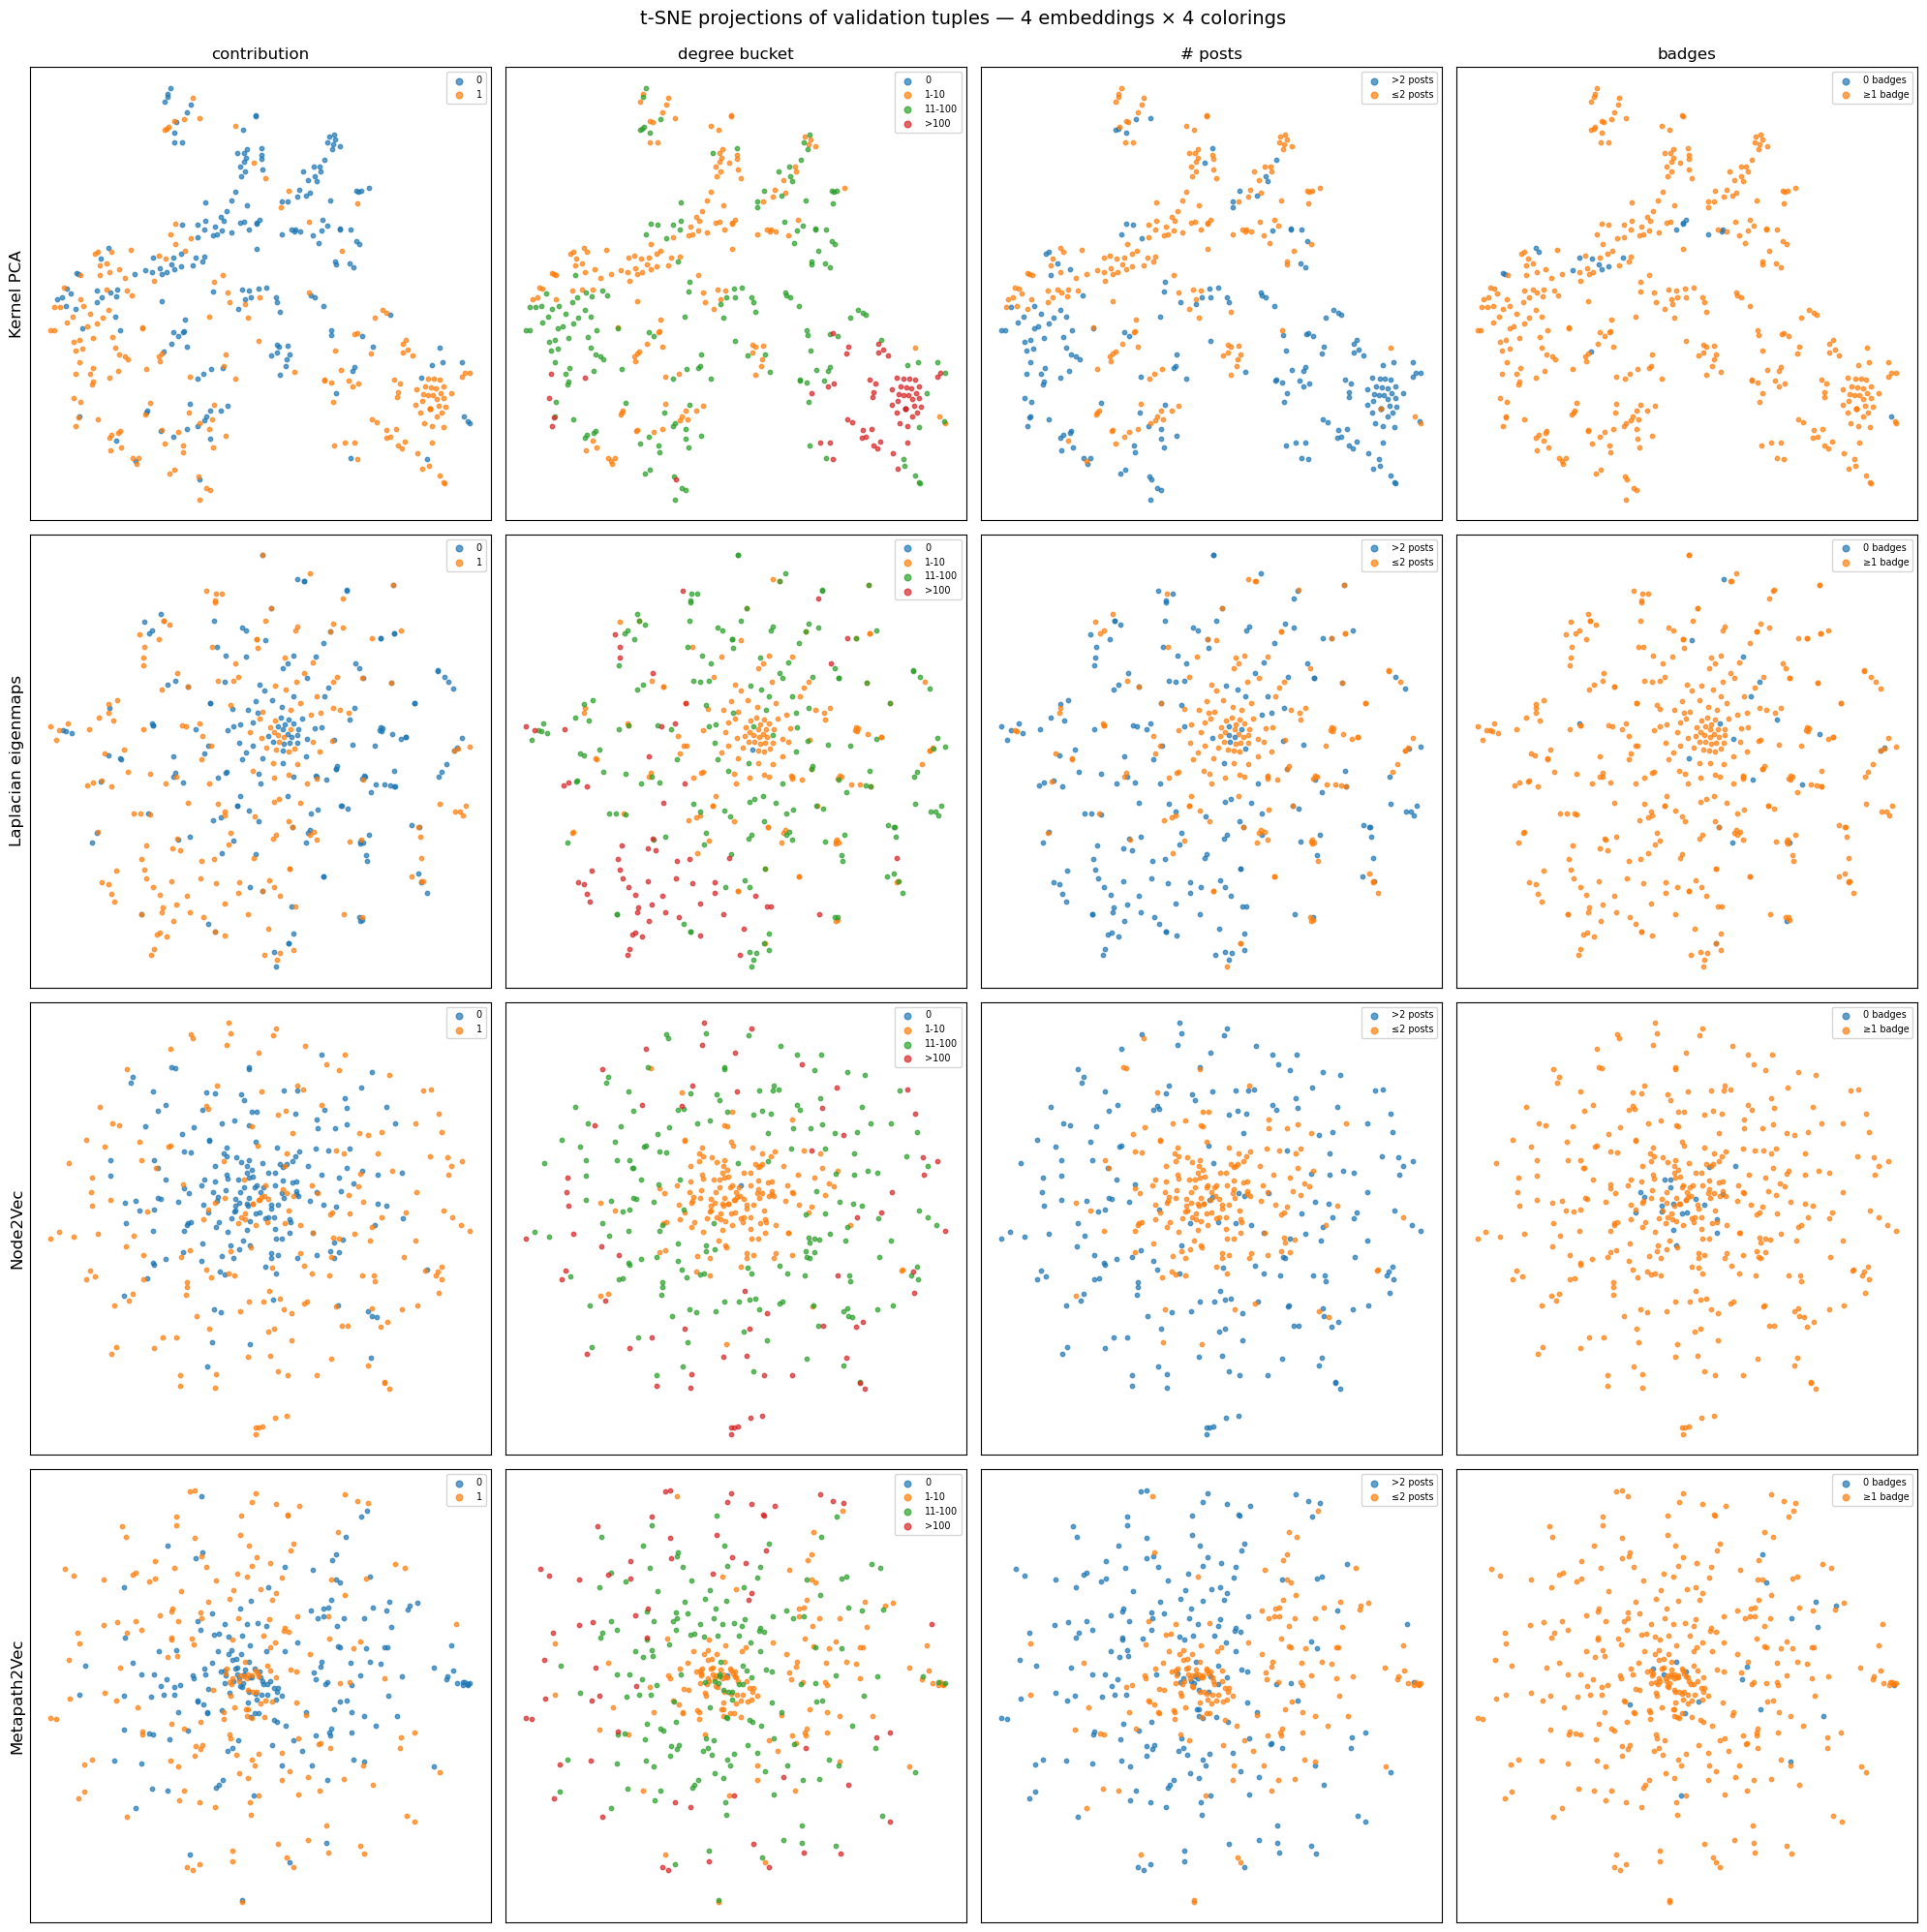

Saved tsne_grid.png


In [ ]:
colorings = [
    ("contribution", labels.astype(str)),
    ("degree bucket", sample_deg_bucket),
    ("# posts",       sample_posts_bucket),
    ("badges",        sample_has_badge),
]
fig, axes = plt.subplots(4, 4, figsize=(20, 20))
for r, (name, xy) in enumerate(tsne_xy.items()):
    for c, (cname, cvec) in enumerate(colorings):
        ax = axes[r, c]
        for v in sorted(np.unique(cvec)):
            m = cvec == v
            ax.scatter(xy[m, 0], xy[m, 1], s=10, label=str(v), alpha=0.7)
        if r == 0: ax.set_title(cname, fontsize=12)
        if c == 0: ax.set_ylabel(name, fontsize=12)
        ax.set_xticks([]); ax.set_yticks([])
        ax.legend(fontsize=7, markerscale=1.5, loc="best")
plt.suptitle("t-SNE projections of validation tuples - 4 embeddings × 4 colorings",
             fontsize=14, y=0.995)
plt.tight_layout()
plt.savefig("/home/wertheizer/structeredML/HW2/tsne_grid.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved tsne_grid.png")

###Q4 - Answer


### Q5. Downstream classification with XGBoost (HW1's best model)


In [ ]:
y_tr = train_df["contribution"].astype(int).values
y_va = val_df["contribution"].astype(int).values
neg, pos = (y_tr == 0).sum(), (y_tr == 1).sum()
spw = neg / max(pos, 1)
XGB_CFG = dict(max_depth=6, n_estimators=300, learning_rate=0.05,
               subsample=0.9, colsample_bytree=0.9,
               scale_pos_weight=spw, n_jobs=-1,
               eval_metric="auc", random_state=42, tree_method="hist")

def evaluate(y_true, y_pred, y_prob):
    return {
        "accuracy":  accuracy_score(y_true, y_pred),
        "roc_auc":   roc_auc_score(y_true, y_prob),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
    }

def eval_xgb(X_tr, y_tr, X_va, y_va, cfg=XGB_CFG, threshold=0.5):
    clf = xgb.XGBClassifier(**cfg)
    clf.fit(X_tr, y_tr)
    p_tr = clf.predict_proba(X_tr)[:, 1]
    p_va = clf.predict_proba(X_va)[:, 1]
    return {
        "train": evaluate(y_tr, (p_tr >= threshold).astype(int), p_tr),
        "val":   evaluate(y_va, (p_va >= threshold).astype(int), p_va),
    }, clf

base_inputs = {
    "Kernel PCA":          (emb_kpca_train, emb_kpca_val),
    "Laplacian eigenmaps": (emb_lap_train,  emb_lap_val),
    "Node2Vec":            (emb_n2v_train,  emb_n2v_val),
    "Metapath2Vec":        (emb_m2v_train,  emb_m2v_val),
}
base_metrics = {}
for name, (Xtr, Xva) in base_inputs.items():
    t0 = time.time()
    m, _ = eval_xgb(Xtr, y_tr, Xva, y_va)
    base_metrics[name] = m
    print(f"{name:22s}  train AUC={m['train']['roc_auc']:.4f}  val AUC={m['val']['roc_auc']:.4f}  ({time.time()-t0:.1f}s)")

def fmt(metrics):
    def pair(t, v):
        return f"{t:.3f}/{v:.3f}"
    return {k: pair(metrics["train"][k], metrics["val"][k])
            for k in ["accuracy", "roc_auc", "precision", "recall", "f1"]}

table_rows = []
for name in ["Kernel PCA", "Laplacian eigenmaps", "Node2Vec", "Metapath2Vec"]:
    row = {"embedding": name}; row.update(fmt(base_metrics[name]))
    table_rows.append(row)
q5_table = pd.DataFrame(table_rows)
print("\nQ5 table (train/val):")
print(q5_table.to_string(index=False))
hb("Q5 base classifier metrics done")

Kernel PCA              train AUC=0.9048  val AUC=0.8968  (23.1s)


Laplacian eigenmaps     train AUC=0.8958  val AUC=0.7899  (22.5s)


Node2Vec                train AUC=0.9142  val AUC=0.8120  (20.7s)


Metapath2Vec            train AUC=0.8964  val AUC=0.7957  (22.4s)

Q5 table (train/val):
          embedding    accuracy     roc_auc   precision      recall          f1
         Kernel PCA 0.815/0.876 0.905/0.897 0.190/0.151 0.829/0.738 0.309/0.251
Laplacian eigenmaps 0.832/0.824 0.896/0.790 0.202/0.097 0.800/0.636 0.322/0.169
           Node2Vec 0.855/0.856 0.914/0.812 0.228/0.117 0.796/0.630 0.354/0.198
       Metapath2Vec 0.828/0.832 0.896/0.796 0.197/0.101 0.792/0.629 0.315/0.174
[14:47:49] Q5 base classifier metrics done


### Q6. Concatenated embeddings


In [ ]:
def cat(a_tr, a_va, b_tr, b_va):
    return np.concatenate([a_tr, b_tr], axis=1), np.concatenate([a_va, b_va], axis=1)

# Pick best base by val AUC
best_name = max(base_metrics, key=lambda n: base_metrics[n]["val"]["roc_auc"])
best_tr, best_va = base_inputs[best_name]
print("Best base embedding by val AUC:", best_name)

combos = {
    "KPCA ⊕ Node2Vec":            cat(emb_kpca_train, emb_kpca_val, emb_n2v_train, emb_n2v_val),
    "KPCA ⊕ Laplacian eigenmaps": cat(emb_kpca_train, emb_kpca_val, emb_lap_train, emb_lap_val),
    "KPCA ⊕ Metapath2Vec":        cat(emb_kpca_train, emb_kpca_val, emb_m2v_train, emb_m2v_val),
    "Node2Vec ⊕ Metapath2Vec":    cat(emb_n2v_train,  emb_n2v_val,  emb_m2v_train, emb_m2v_val),
    f"{best_name} ⊕ {best_name}": cat(best_tr, best_va, best_tr, best_va),
}
combo_metrics = {}
for name, (Xtr, Xva) in combos.items():
    t0 = time.time()
    m, _ = eval_xgb(Xtr, y_tr, Xva, y_va)
    combo_metrics[name] = m
    print(f"{name:36s}  train AUC={m['train']['roc_auc']:.4f}  val AUC={m['val']['roc_auc']:.4f}  ({time.time()-t0:.1f}s)")

for name, m in combo_metrics.items():
    row = {"embedding": name}; row.update(fmt(m))
    table_rows.append(row)
q6_table = pd.DataFrame(table_rows)
print("\nFull table (Q5+Q6):")
print(q6_table.to_string(index=False))
hb("Q6 concat classifier metrics done")

Best base embedding by val AUC: Kernel PCA


KPCA ⊕ Node2Vec                       train AUC=0.9395  val AUC=0.8900  (45.9s)


KPCA ⊕ Laplacian eigenmaps            train AUC=0.9324  val AUC=0.8789  (49.6s)


KPCA ⊕ Metapath2Vec                   train AUC=0.9305  val AUC=0.8874  (49.8s)


Node2Vec ⊕ Metapath2Vec               train AUC=0.9171  val AUC=0.8162  (45.1s)


Kernel PCA ⊕ Kernel PCA               train AUC=0.9049  val AUC=0.8964  (48.3s)

Full table (Q5+Q6):
                 embedding    accuracy     roc_auc   precision      recall          f1
                Kernel PCA 0.815/0.876 0.905/0.897 0.190/0.151 0.829/0.738 0.309/0.251
       Laplacian eigenmaps 0.832/0.824 0.896/0.790 0.202/0.097 0.800/0.636 0.322/0.169
                  Node2Vec 0.855/0.856 0.914/0.812 0.228/0.117 0.796/0.630 0.354/0.198
              Metapath2Vec 0.828/0.832 0.896/0.796 0.197/0.101 0.792/0.629 0.315/0.174
           KPCA ⊕ Node2Vec 0.863/0.910 0.940/0.890 0.249/0.185 0.864/0.651 0.387/0.288
KPCA ⊕ Laplacian eigenmaps 0.851/0.905 0.932/0.879 0.232/0.175 0.860/0.643 0.365/0.275
       KPCA ⊕ Metapath2Vec 0.846/0.896 0.931/0.887 0.226/0.168 0.860/0.680 0.358/0.269
   Node2Vec ⊕ Metapath2Vec 0.842/0.844 0.917/0.816 0.216/0.111 0.819/0.649 0.342/0.189
   Kernel PCA ⊕ Kernel PCA 0.815/0.876 0.905/0.896 0.190/0.151 0.829/0.734 0.310/0.250
[14:51:50] Q6 concat classifi

### Q7


###Q8


### Q9. Qualitative analysis — 2-hop neighborhoods


Building adjacency lists for 2-hop queries...
Done.
Chosen focal users (OwnerUserId, homo_idx, degree): [(224757, 2820265, 26), (11323, 2606831, 49), (132532, 2728040, 43)]
Building user -> KPCA embedding map...
  255,360 users have a KPCA embedding

=== User 224757 (idx 2820265, deg 26) - 2-hop neighbor similarities ===
 hop    node        type same_user  Kernel PCA  Laplacian  Node2Vec  Metapath2Vec
   1  426736      badges       yes       1.000      0.218     0.667           NaN
   1  428255      badges       yes       1.000      0.218     0.676           NaN
   1 1005628    comments       yes       1.000      0.217     0.658         0.162
   1 1023126    comments       yes       1.000      0.288     0.595         0.320
   1 2569812       posts       yes       1.000      0.002     0.611         0.033
   1 2575881       posts       yes       1.000      0.041     0.726         0.144
   1 2101699 postHistory       yes       1.000      0.217     0.650           NaN
   1 2101700 postHist

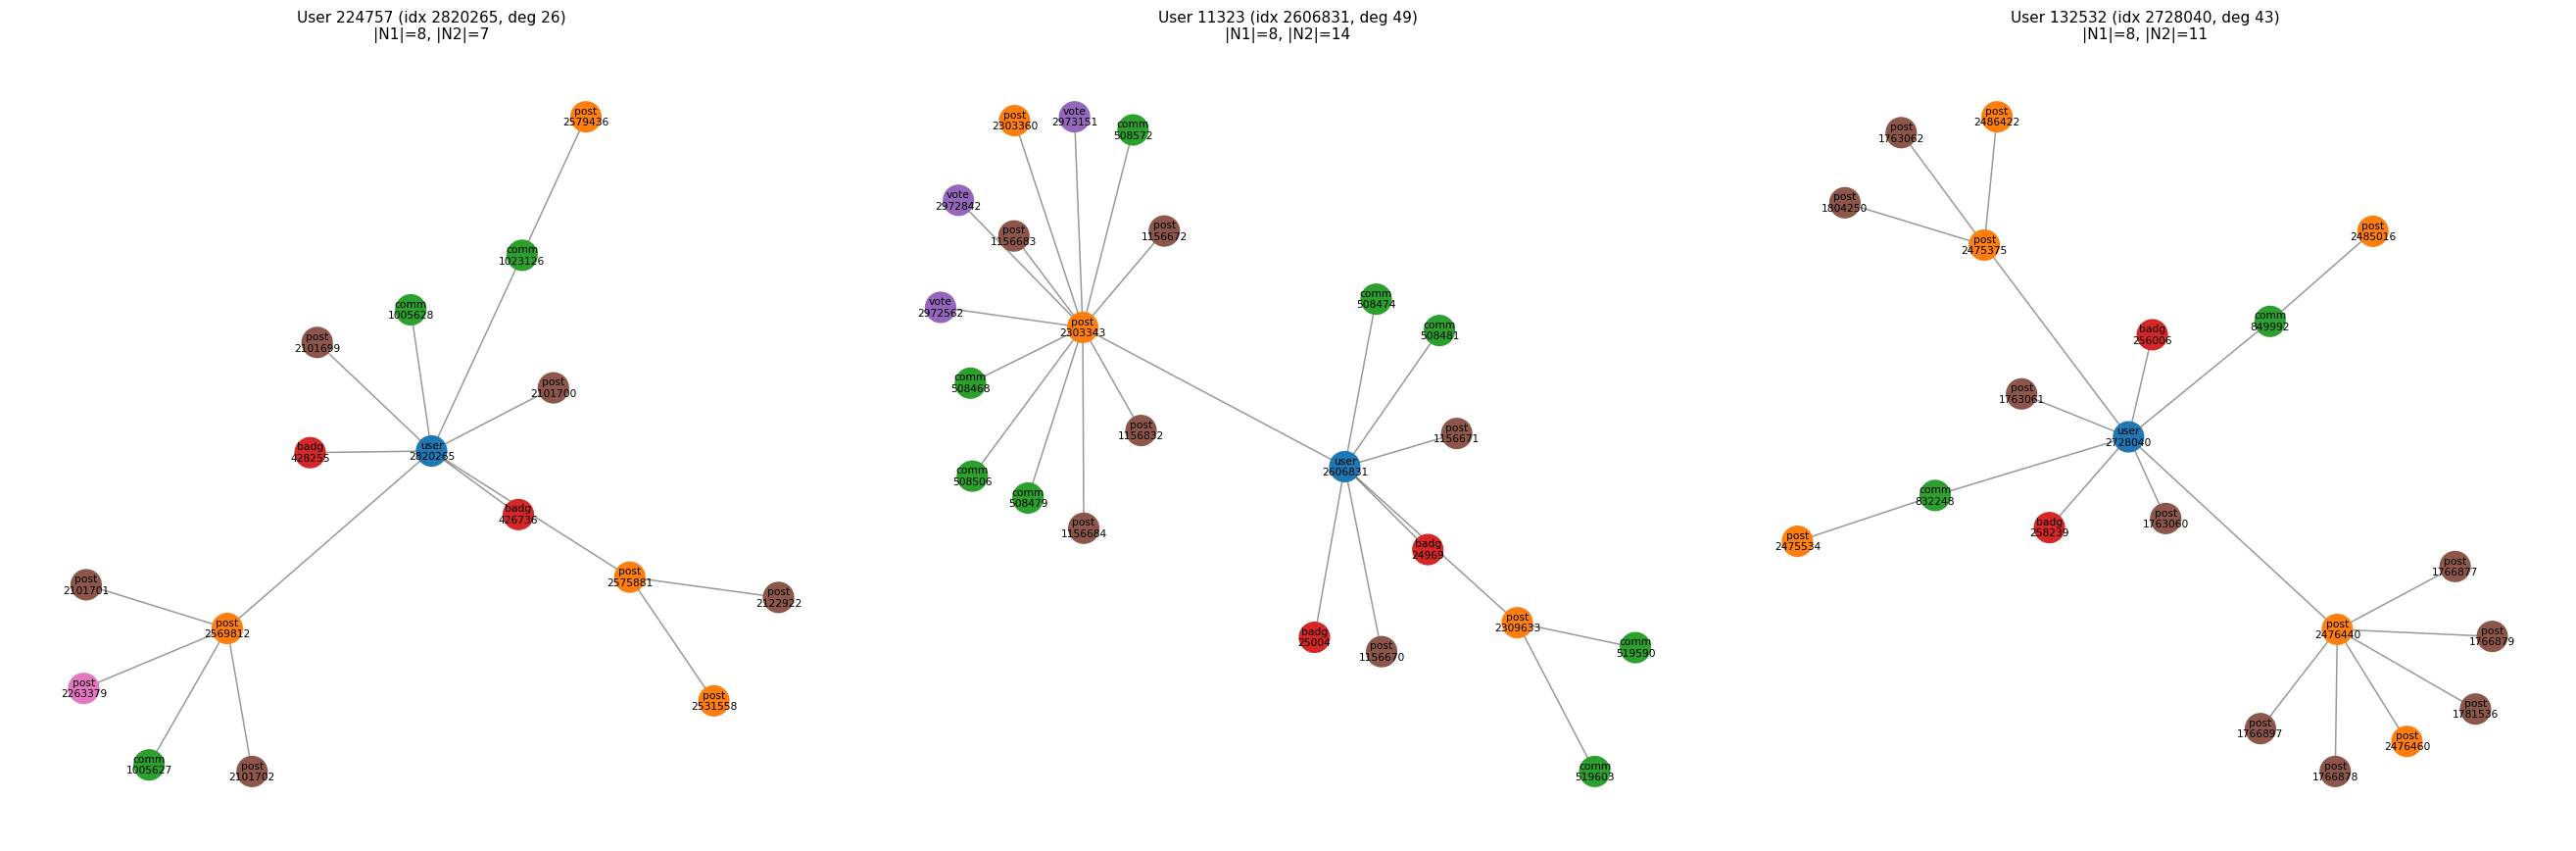

In [99]:
# Build an undirected neighbor list for fast lookup
print("Building adjacency lists for 2-hop queries...")
neigh = [list() for _ in range(N)]
for s, t in und_pairs:
    neigh[s].append(t); neigh[t].append(s)
print("Done.")

# Helper: type label for a homogeneous node index
type_starts = [(offsets[nt], offsets[nt] + hetero[nt].num_nodes, nt) for nt in node_types]
def node_type(idx):
    for s, e, nt in type_starts:
        if s <= idx < e: return nt
    return "?"

def cos_sim(a, b, eps=1e-9):
    if a is None or b is None: return float("nan")
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    if na < eps or nb < eps: return 0.0
    return float(np.dot(a, b) / (na * nb))


def two_hop_subgraph(center, max_per_hop=10):
    hop1 = neigh[center][:max_per_hop]
    seen = {center, *hop1}
    hop2 = []
    for v in hop1:
        for w in neigh[v]:
            if w in seen: continue
            seen.add(w); hop2.append((v, w))
            if len([1 for _, x in hop2 if _ == v]) >= max_per_hop:
                break
    return hop1, hop2


# Pick 3 users with moderate-to-high degree from the *validation* sample for variety
candidate_users = []
for oid in val_df["OwnerUserId"].dropna().unique():
    loc = users_local_idx.get(int(oid), -1)
    if loc < 0: continue
    homo_idx = u_off + loc
    d = deg[homo_idx]
    if 5 <= d <= 50:
        candidate_users.append((int(oid), homo_idx, int(d)))
    if len(candidate_users) >= 50: break
rng2 = np.random.default_rng(0)
sel = rng2.choice(len(candidate_users), size=3, replace=False)
chosen = [candidate_users[i] for i in sel]
print("Chosen focal users (OwnerUserId, homo_idx, degree):", chosen)


# --- Metapath2Vec embeddings live per type (users/posts/comments) ---
m2v_user = emb_m2v_by_type["users"]
m2v_post = emb_m2v_by_type["posts"]
m2v_comment = emb_m2v_by_type["comments"]

def m2v_emb_for(homo_idx):
    nt = node_type(homo_idx)
    if nt == "users":    return m2v_user[homo_idx - offsets["users"]]
    if nt == "posts":    return m2v_post[homo_idx - offsets["posts"]]
    if nt == "comments": return m2v_comment[homo_idx - offsets["comments"]]
    return None


# --- Kernel PCA embedding lookup via the "connected user" ---
# Q9 spec edit: For Kernel PCA, since an embedding is only available for nodes
# of type User, if the node is of a different type (comment, post, etc.) use
# the embedding of the user connected to it.
#
# Per-user KPCA embedding: pick the first occurrence of the user across
# train_feat (then val_feat as fallback). KPCA was learned at the tuple level,
# so we use one representative tuple per user.
print("Building user -> KPCA embedding map...")
user_to_kpca = {}
for i, oid in enumerate(train_df["OwnerUserId"].values):
    if pd.notna(oid):
        oid = int(oid)
        if oid not in user_to_kpca:
            user_to_kpca[oid] = emb_kpca_train[i]
for i, oid in enumerate(val_df["OwnerUserId"].values):
    if pd.notna(oid):
        oid = int(oid)
        if oid not in user_to_kpca:
            user_to_kpca[oid] = emb_kpca_val[i]
print(f"  {len(user_to_kpca):,} users have a KPCA embedding")

# Map any homogeneous node index -> the user_id it is "connected to"
# - users:        themselves
# - posts:        OwnerUserId
# - comments:     UserId
# - badges:       UserId
# - votes:        UserId
# - postHistory:  UserId
# - postLinks:    PostId -> posts.OwnerUserId  (an extra hop)
posts_id_to_owner = dict(zip(db.table_dict["posts"].df["Id"].astype("int64"),
                              db.table_dict["posts"].df["OwnerUserId"]))

def homo_to_user_id(homo_idx):
    nt = node_type(homo_idx)
    local = homo_idx - offsets[nt]
    df = hetero._dfs[nt]
    if local < 0 or local >= len(df): return None
    row = df.iloc[local]
    if nt == "users":   return int(row["Id"])
    user_fk_col = {"posts": "OwnerUserId",
                    "comments": "UserId",
                    "badges": "UserId",
                    "votes": "UserId",
                    "postHistory": "UserId"}.get(nt)
    if user_fk_col is not None:
        v = row[user_fk_col]
        return int(v) if pd.notna(v) else None
    if nt == "postLinks":
        pid = row["PostId"]
        if pd.isna(pid): return None
        owner = posts_id_to_owner.get(int(pid))
        return int(owner) if (owner is not None and pd.notna(owner)) else None
    return None

def kpca_emb_for(homo_idx):
    uid = homo_to_user_id(homo_idx)
    if uid is None: return None
    return user_to_kpca.get(uid)


fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for ax_i, (oid, center, d) in enumerate(chosen):
    hop1, hop2 = two_hop_subgraph(center, max_per_hop=8)
    nodes_used = [center] + hop1 + [w for _, w in hop2]
    nodes_used = list(dict.fromkeys(nodes_used))  # de-dupe, preserve order
    g = nx.Graph()
    for v in nodes_used:
        g.add_node(v, label=f"{node_type(v)[:4]}\n{v}")
    for v in hop1:
        g.add_edge(center, v)
    for u, w in hop2:
        g.add_edge(u, w)
    pos = nx.spring_layout(g, seed=42)
    type_to_color = {"users":"#1f77b4", "posts":"#ff7f0e", "comments":"#2ca02c",
                     "badges":"#d62728", "votes":"#9467bd", "postHistory":"#8c564b",
                     "postLinks":"#e377c2"}
    colors = [type_to_color.get(node_type(v), "#7f7f7f") for v in g.nodes]
    nx.draw_networkx_nodes(g, pos, node_color=colors, node_size=400, ax=axes[ax_i])
    nx.draw_networkx_edges(g, pos, alpha=0.4, ax=axes[ax_i])
    labels = {v: f"{node_type(v)[:4]}\n{v}" for v in g.nodes}
    nx.draw_networkx_labels(g, pos, labels, font_size=7, ax=axes[ax_i])
    axes[ax_i].set_title(f"User {oid} (idx {center}, deg {d})\n"
                          f"|N1|={len(hop1)}, |N2-only|={len([w for _,w in hop2])}",
                          fontsize=10)
    axes[ax_i].axis("off")

    # Cos-sim table per neighbor in each of the 4 base embeddings
    sim_rows = []
    for v in nodes_used[1:]:
        row = {"node": v, "type": node_type(v),
               "Kernel PCA": cos_sim(kpca_emb_for(center), kpca_emb_for(v)),
               "Laplacian":  cos_sim(emb_lap[center], emb_lap[v]),
               "Node2Vec":   cos_sim(emb_n2v[center], emb_n2v[v]),
               "Metapath2Vec": cos_sim(m2v_emb_for(center), m2v_emb_for(v))}
        sim_rows.append(row)
    sim_df = pd.DataFrame(sim_rows).round(3)
    print(f"\n=== User {oid} (idx {center}, deg {d}) - 2-hop neighbor similarities ===")
    print(sim_df.to_string(index=False))

plt.tight_layout()
plt.savefig("/home/wertheizer/structeredML/HW2/neighborhoods.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved neighborhoods.png")
hb("Q9 neighborhood viz done - NOTEBOOK COMPLETE")


### Q9. Observations


## Part 3 - Dry answers


### Q10. Encoder-decoder paradigm per method


### Q11. Why embedding methods are usually considered task-agnostic


### Q12. Two strategies for handling a large matrix


### Q13. Walk length vs metapath length in Metapath2Vec


### Q14. Conclusion


### Q15. Packages used beyond the spec.


## Q16 - AI-tool usage
